#Task 1: Linear Regression

#1- Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#2- Load and explore the dataset

In [ ]:
df = pd.read_csv('/content/movies_metadata.csv')

print("Dataset Shape:", df.shape)
print(df.info())
print(df.isnull().sum())

df.head()

/tmp/ipykernel_1137/720552593.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/movies_metadata.csv')


Dataset Shape: (45466, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           4537

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


#3- Select columns and clean the data

In [ ]:
movie_data = df[['budget', 'popularity', 'runtime', 'vote_count', 'revenue']].copy()

cols = ['budget', 'popularity', 'runtime', 'vote_count', 'revenue']

for col in cols:
    movie_data[col] = pd.to_numeric(movie_data[col], errors='coerce')

movie_data = movie_data.replace([np.inf, -np.inf], np.nan)
movie_data = movie_data.dropna()

movie_data = movie_data[
    (movie_data['budget'] > 0) &
    (movie_data['revenue'] > 0)
].copy()

print("Rows after cleaning:", movie_data.shape[0])
movie_data.head()

Rows after cleaning: 5380


,budget,popularity,runtime,vote_count,revenue
0,30000000.0,21.946943,81.0,5415.0,373554033.0
1,65000000.0,17.015539,104.0,2413.0,262797249.0
3,16000000.0,3.859495,127.0,34.0,81452156.0
5,60000000.0,17.924927,170.0,1886.0,187436818.0
8,35000000.0,5.231580,106.0,174.0,64350171.0


#4- Separate features and target, then split the data

In [ ]:
X = movie_data[['budget', 'popularity', 'runtime', 'vote_count']]
y = movie_data['revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 4304
Testing rows: 1076


#5- Train the Linear Regression model

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


#6- Predict and evaluate

In [ ]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 44268027.55790349
Root Mean Squared Error: 78716391.89565675
R2 Score: 0.7425491847332057


#7- Compare actual and predicted revenue

       Actual Revenue  Predicted Revenue
1889       30749142.0       2.072500e+07
30573      19660000.0       4.163405e+06
3275       39321715.0       2.450301e+07
3765       15843608.0       4.063648e+07
44856       1957000.0      -1.505471e+07
10010      71073932.0       1.391403e+08
15499        317000.0       1.273916e+07
1660       64256513.0       3.025920e+07
5430       34411240.0       6.404340e+06
45399             3.0      -2.062706e+07


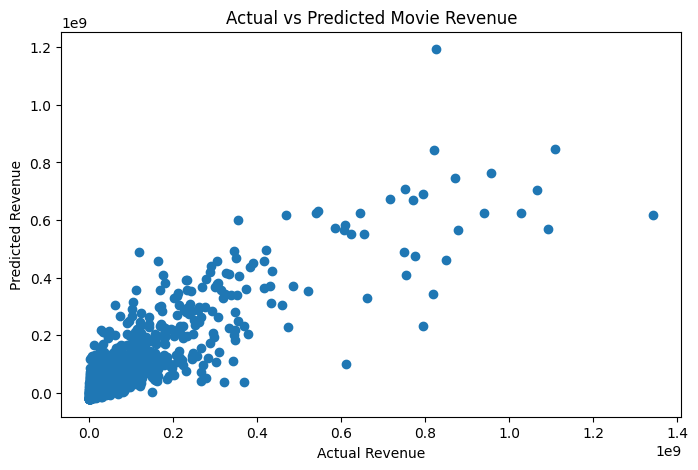

In [ ]:
results = pd.DataFrame({
    'Actual Revenue': y_test,
    'Predicted Revenue': y_pred
})

print(results.head(10))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Movie Revenue")
plt.show()

#Task 2 - Logistic Regression

#1- Create categories for Logistic Regression

In [ ]:
movie_data['profitable'] = (
    movie_data['revenue'] > movie_data['budget']
).astype(int)

X_log = movie_data[['budget', 'popularity', 'runtime', 'vote_count']]
y_log = movie_data['profitable']

print(y_log.value_counts())

profitable
1    3756
0    1624
Name: count, dtype: int64


#2- Split the data and train Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log
)

log_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

log_model.fit(X_train_log, y_train_log)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


#3- Predict and evaluate

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_log = log_model.predict(X_test_log)

print("Accuracy:", accuracy_score(y_test_log, y_pred_log))
print("\nClassification Report:\n")
print(classification_report(y_test_log, y_pred_log, zero_division=0))

print("Confusion Matrix:\n")
print(confusion_matrix(y_test_log, y_pred_log))

Accuracy: 0.7481412639405205

Classification Report:

              precision    recall  f1-score   support

           0       0.72      0.27      0.39       325
           1       0.75      0.96      0.84       751

    accuracy                           0.75      1076
   macro avg       0.74      0.61      0.62      1076
weighted avg       0.74      0.75      0.71      1076

Confusion Matrix:

[[ 87 238]
 [ 33 718]]
